# Fig. 4D: mouse pseudotime on the tissue sections

Reads the mouse fibroblast/decidual object (`MOUSE`) and writes one panel per timepoint into `OUT`, plus a color
key. `OUT` must be a new folder outside `xmens_figures`; copy checked panels into
`xmens_figures/final_figures/Fig4_mouse_decidual_maturation/` by hand.

Panel 4H (the pseudotime gene heatmap) is made in `pt_heatmaps/`, not here.

How the panels are drawn:

- Crops and rotations are those of the cell-type section panels (Ç. Cevrim's script, 11 Oct 2026; angles from
  `mouse_section_rotation.yaml`). Positions are `x_um_dbscan`, `y_um_dbscan`; the November objects have no
  spatially QC'd positions.
- Color is `obs['pseudotime']` as stored, on one viridis scale from 0 to 1 for all panels.
- Apoptotic decidual nuclei (`cell_subtype` decAp, which carry no pseudotime) are not drawn; every other positioned
  nucleus of the crop is. The decAp nuclei still count toward the crop, the center of rotation and the axis limits,
  so the framing is that of the version with them in grey.
- Font: Helvetica Neue if `FONT_FILE` points to it, otherwise DejaVu Sans.

There is no earlier version of 4D in `final_figures/`; this is a new panel (10 Nov 2026).

In [1]:
# Parameters (papermill -p NAME VALUE overrides them)
OUT = ""  # a new folder for this figure's panels
MOUSE = "/n/lab_storage/eddy_lab/Lab/mckinley/data/20261110_mouse_only_eFib_dec_final_nick_pdt.h5ad"
FONT_FILE = ""  # a Helvetica Neue font file (optional); empty: DejaVu Sans
DATE = "20261110"  # file-name prefix of the panels
APOPTOTIC_SUBTYPE = "decAp"  # obs cell_subtype left out of the panels (no pseudotime)

In [2]:
import datetime
import hashlib
import json
import platform
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from IPython.display import Image, display
from matplotlib import font_manager

OUT = Path(OUT)
assert OUT.name, "set OUT, the folder for this figure's panels"
assert "xmens_figures" not in OUT.resolve().parts, "write to OUT; copy checked panels into xmens_figures by hand"
assert not OUT.exists(), f"{OUT} exists; use a new folder"
OUT.mkdir(parents=True)


def set_up_font(font_file: str) -> str:
    """Helvetica Neue from a font file if given, otherwise DejaVu Sans; returns the family in use."""
    family = ["DejaVu Sans"]
    if font_file:
        font_manager.fontManager.addfont(font_file)
        family = ["Helvetica Neue", "DejaVu Sans"]
    mpl.rcParams.update({"font.family": family, "svg.fonttype": "none", "pdf.fonttype": 42})
    return font_manager.FontProperties(family=family).get_name()


def file_record(path: Path, role: str) -> dict:
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 24), b""):
            digest.update(block)
    return {"path": str(path.resolve()), "role": role, "bytes": path.stat().st_size, "sha256": digest.hexdigest()}


font = set_up_font(FONT_FILE)
obs = sc.read_h5ad(MOUSE, backed="r").obs[["sample", "timepoint", "cell_type", "cell_subtype", "x_um_dbscan",
                                           "y_um_dbscan", "pseudotime"]]
positioned = obs[obs[["x_um_dbscan", "y_um_dbscan"]].notna().all(axis=1)]
# The apoptotic decidual nuclei (decAp) carry no pseudotime and are left out of the panels. They still count
# toward each section's crop, center of rotation and axis limits, so the framing is unchanged.
apoptotic = positioned["cell_subtype"].astype(str) == APOPTOTIC_SUBTYPE
assert (positioned["pseudotime"].isna() == apoptotic).all(), "nuclei without a pseudotime are not exactly decAp"
print(f"font: {font}")
print(f"{len(obs):,} nuclei; {len(positioned):,} positioned, {int(apoptotic.sum()):,} of them {APOPTOTIC_SUBTYPE} "
      f"(not drawn)")

font: DejaVu Sans
42,966 nuclei; 25,120 positioned, 595 of them decAp (not drawn)


## 4D · pseudotime on the mouse sections

One bare 6 x 6 in panel per timepoint on black (300 dpi, no text) plus a horizontal color key. The libraries of a
timepoint share one coordinate frame and are drawn together. Crops are in raw coordinates (so they select the same
nuclei whatever the angle); the uninduced crop keeps one of the array's two tissue pieces. Rotations are
counter-clockwise, about the center of the crop (or of the drawn nuclei), as in the cell-type panels.

4D uninduced: {'libraries': ['uninduced_mck8a', 'uninduced_mck8b'], 'positioned': 4180, 'in_crop': 2041, 'apoptotic_not_drawn': 0, 'drawn': 2041, 'median_pseudotime': 0.2859, 'limits_um': [(3350, 5850), (500, 3000)], 'rotation_deg_ccw': 322.75}
4D 1.5dpi_early: {'libraries': ['1.5dpi_early_mck1'], 'positioned': 1525, 'in_crop': 1479, 'apoptotic_not_drawn': 3, 'drawn': 1476, 'median_pseudotime': 0.3993, 'limits_um': [(1000, 3000), (1000, 3000)], 'rotation_deg_ccw': 28}
4D 1.5dpi_late: {'libraries': ['1.5dpi_late_mck12a', '1.5dpi_late_mck12b'], 'positioned': 5890, 'in_crop': 5890, 'apoptotic_not_drawn': 37, 'drawn': 5853, 'median_pseudotime': 0.4194, 'limits_um': None, 'rotation_deg_ccw': 303}
4D 2.5dpi: {'libraries': ['2.5dpi_mck15'], 'positioned': 2132, 'in_crop': 2117, 'apoptotic_not_drawn': 5, 'drawn': 2112, 'median_pseudotime': 0.5109, 'limits_um': [(2000, 9500), (500, 6500)], 'rotation_deg_ccw': 175}
4D 3.5dpi: {'libraries': ['3.5dpi_mck10a', '3.5dpi_mck10b'], 'positioned': 6755, '

/tmp/ipykernel_2947960/309897453.py:116: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  "versions": {"python": platform.python_version(), "scanpy": sc.__version__, "matplotlib": mpl.__version__,


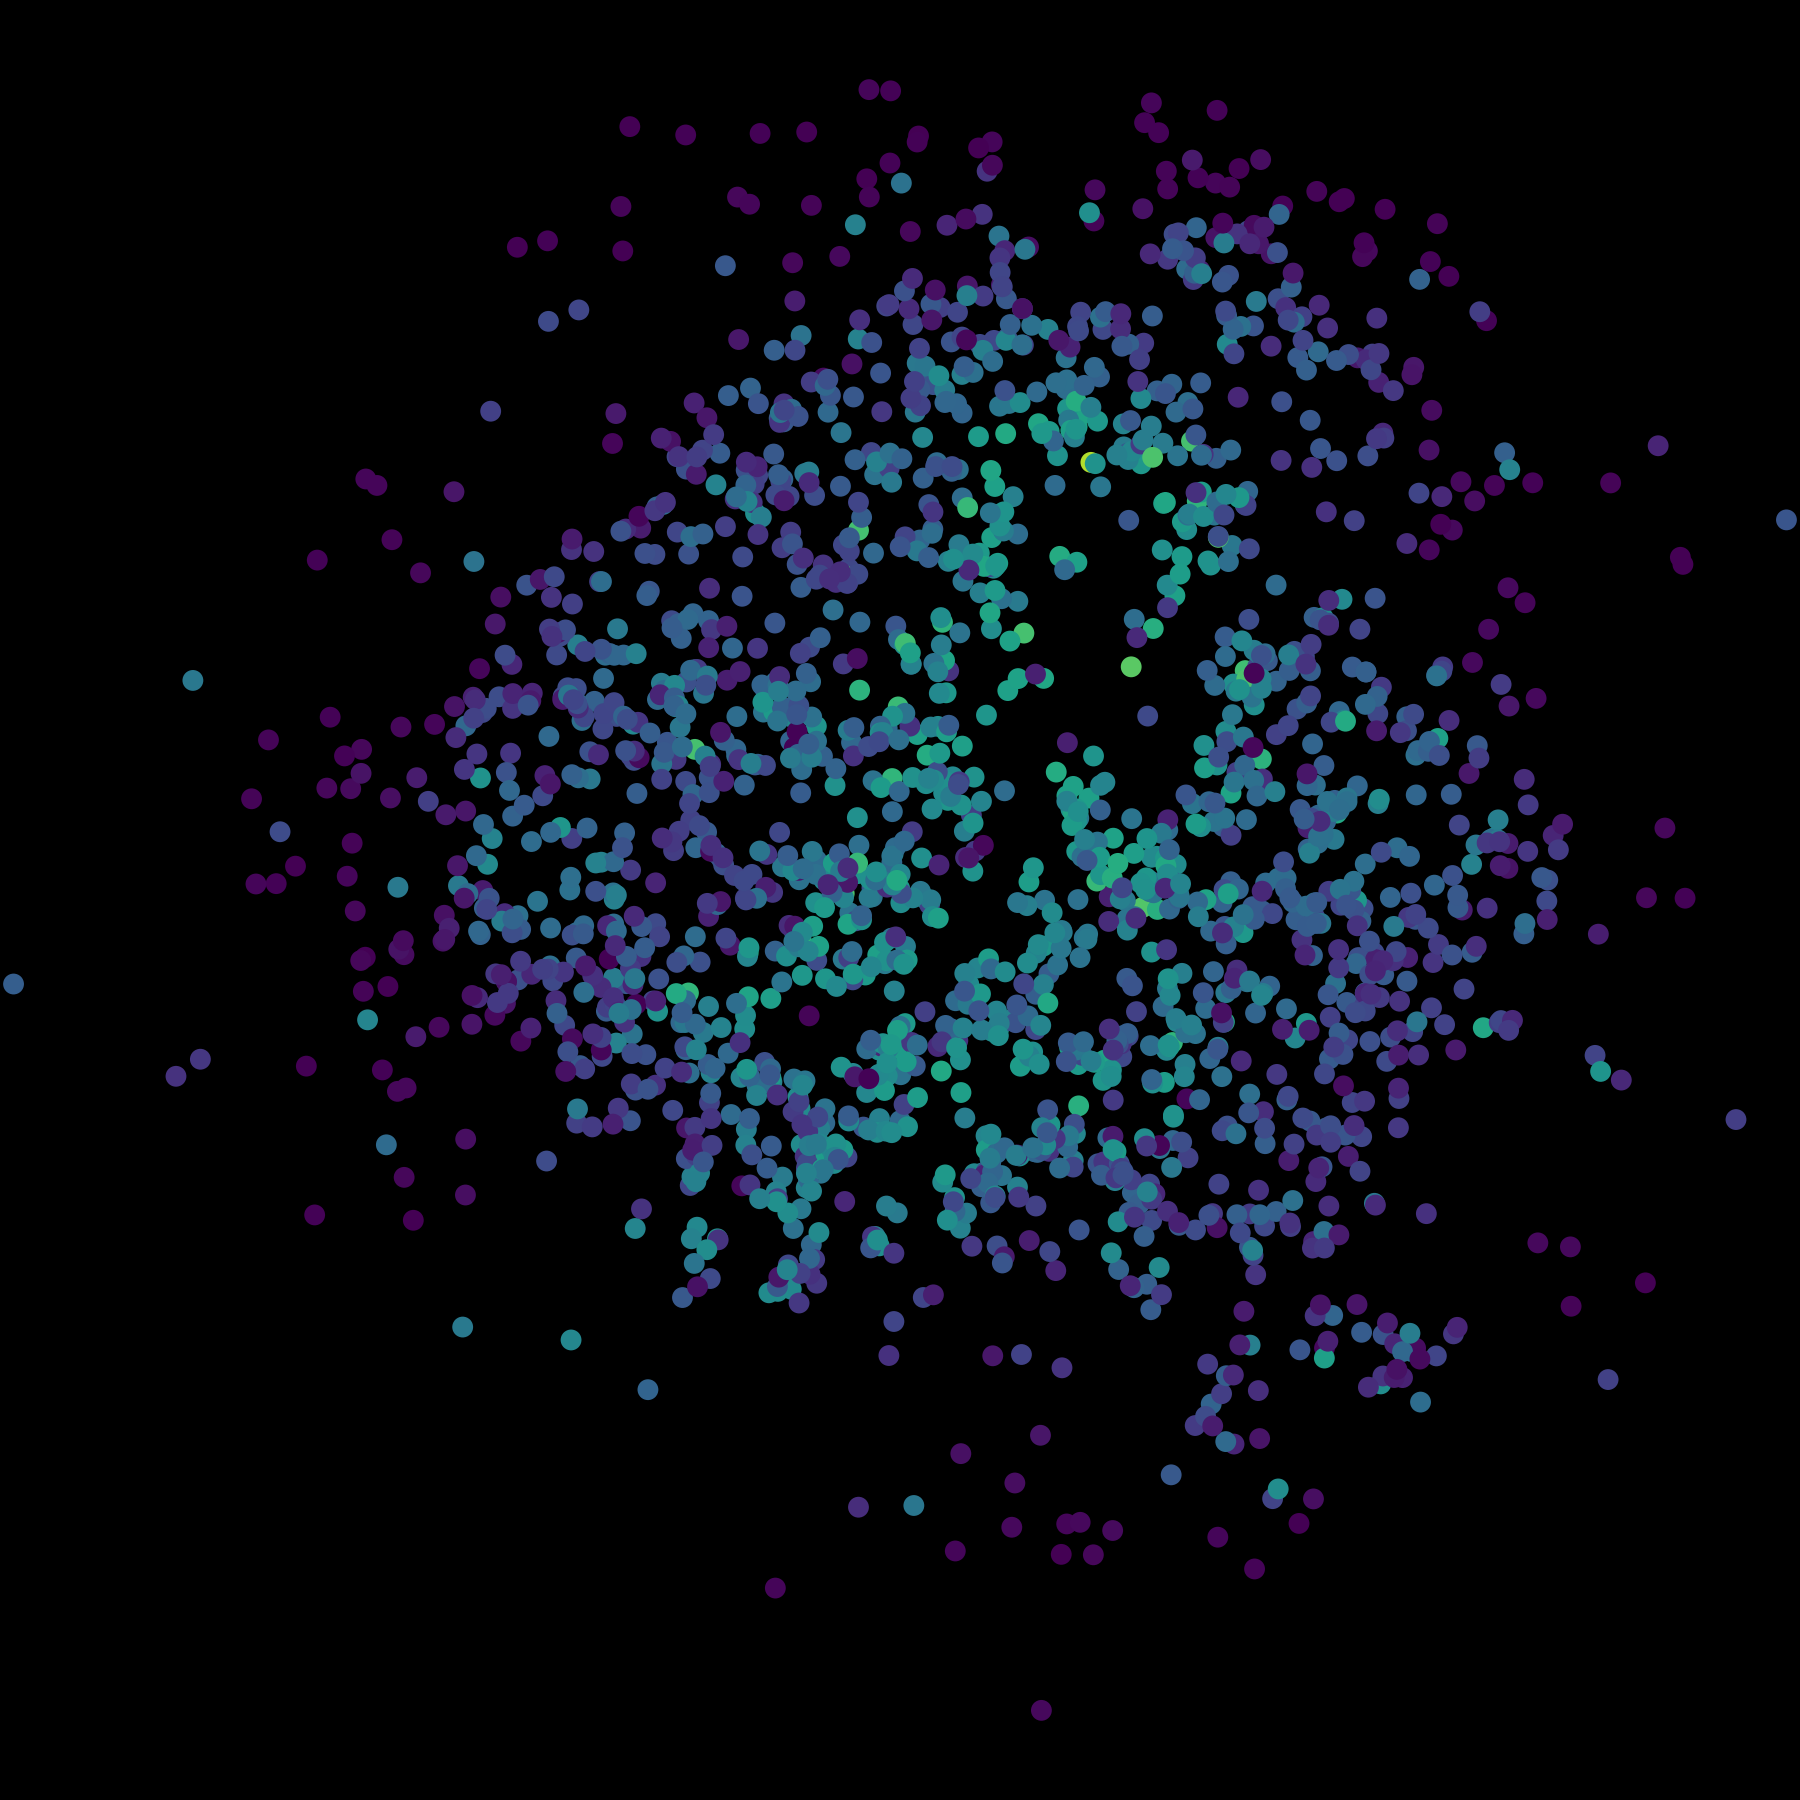

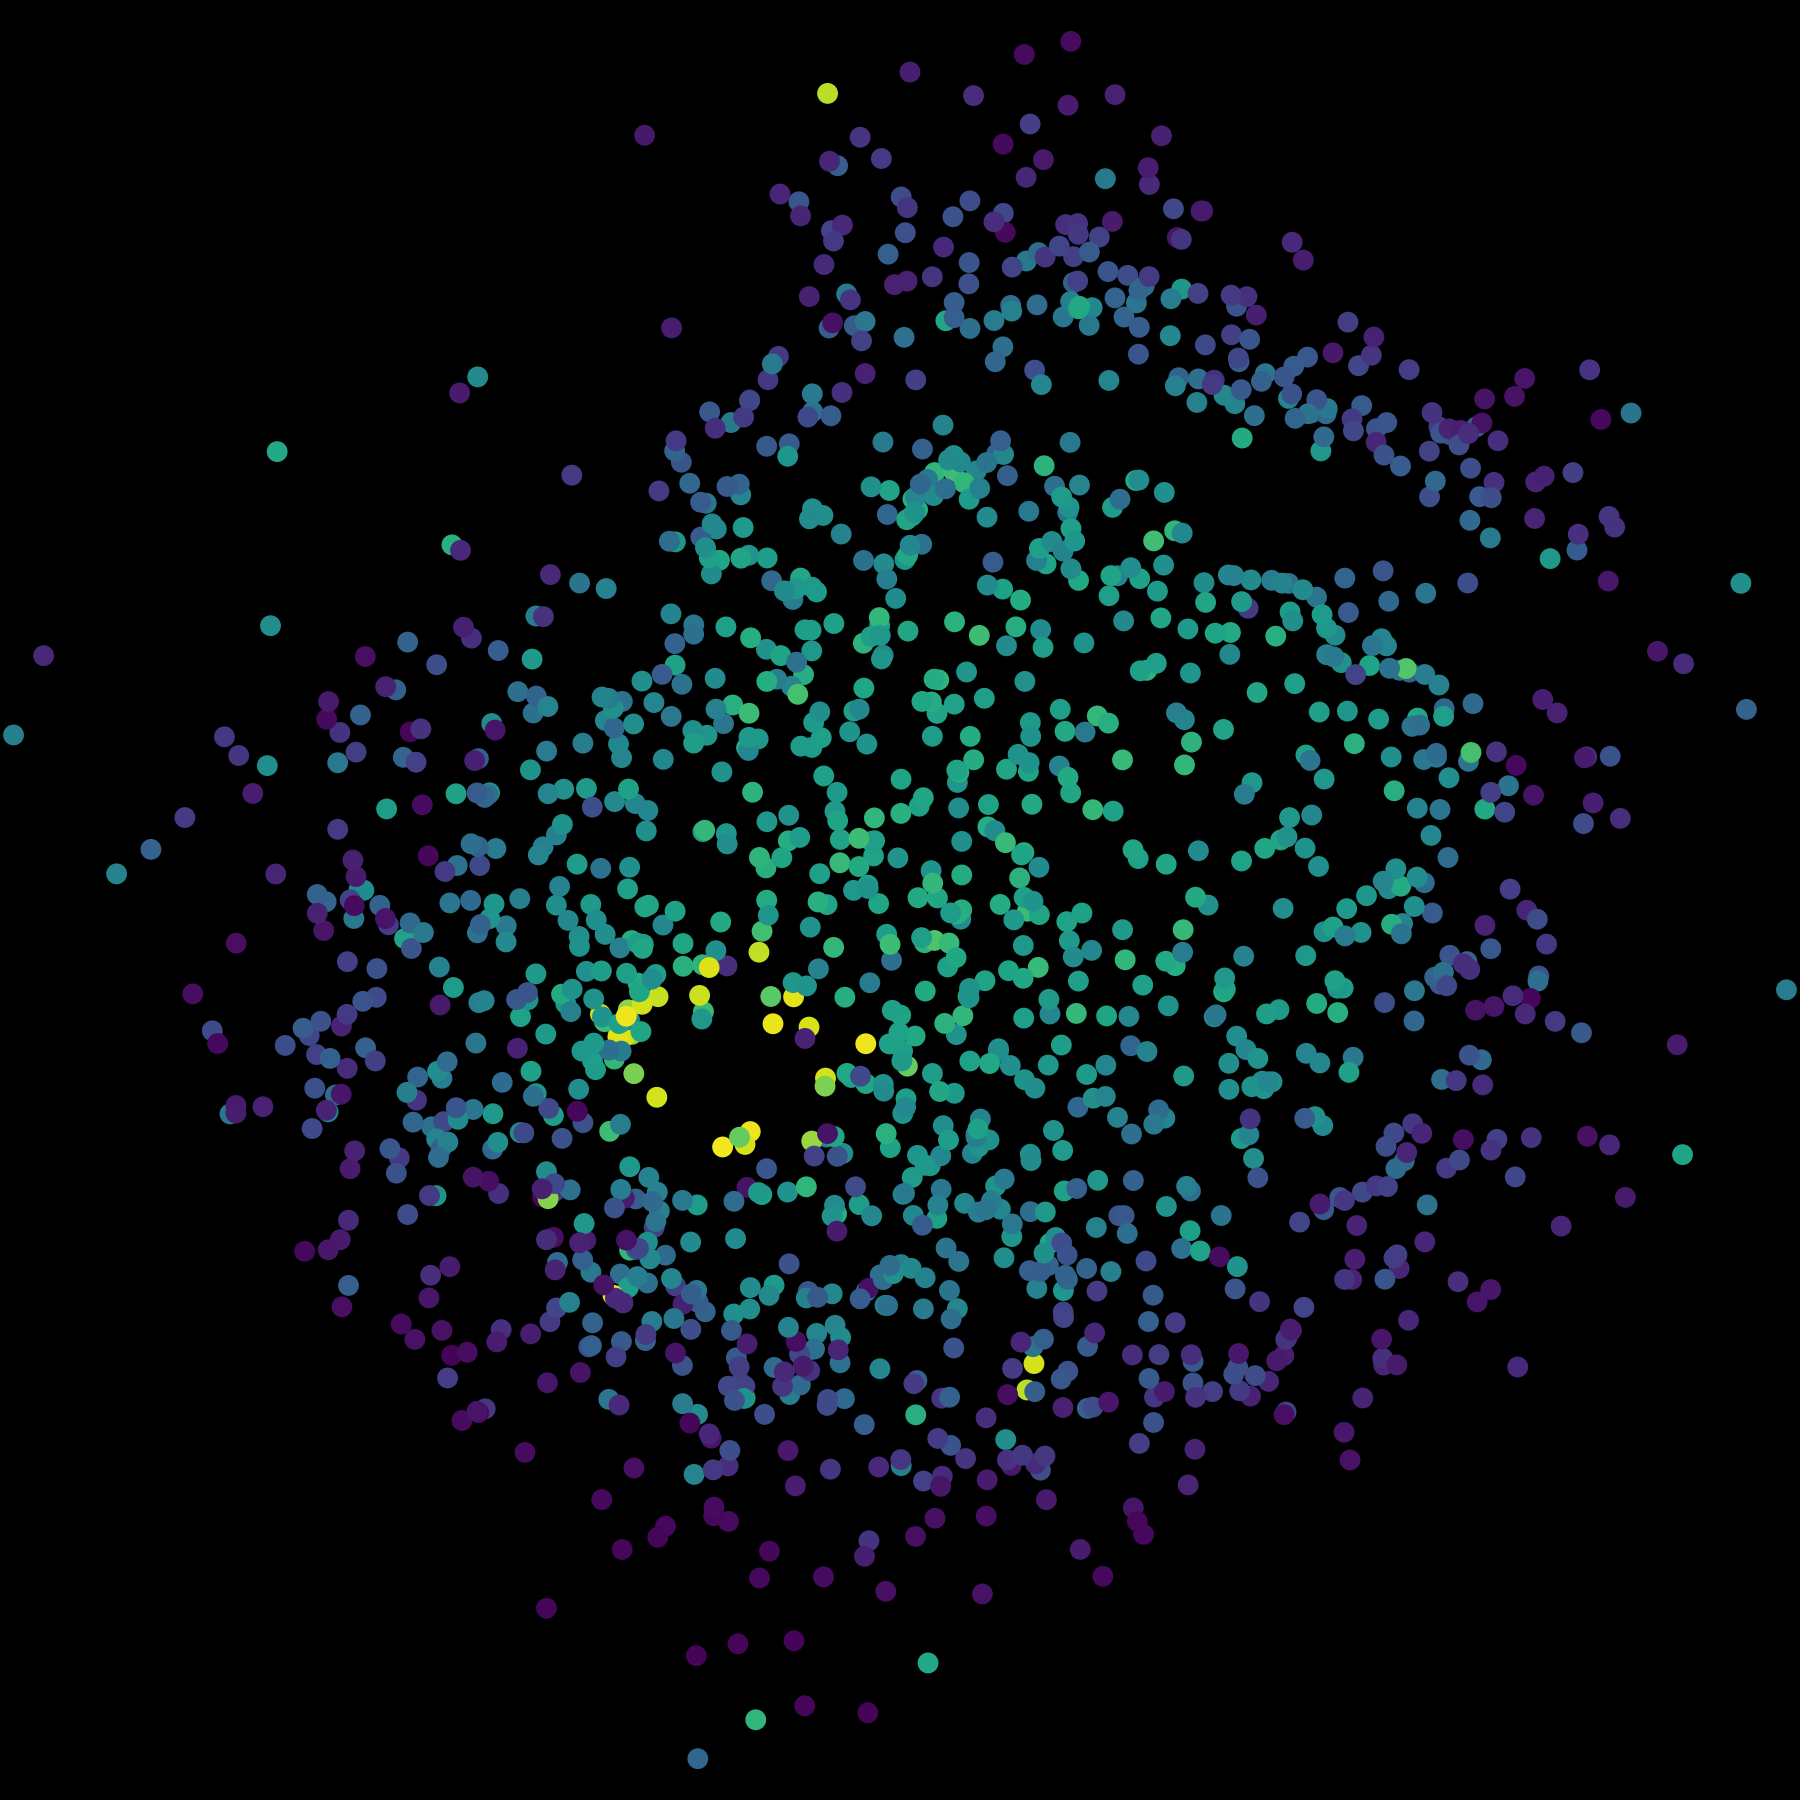

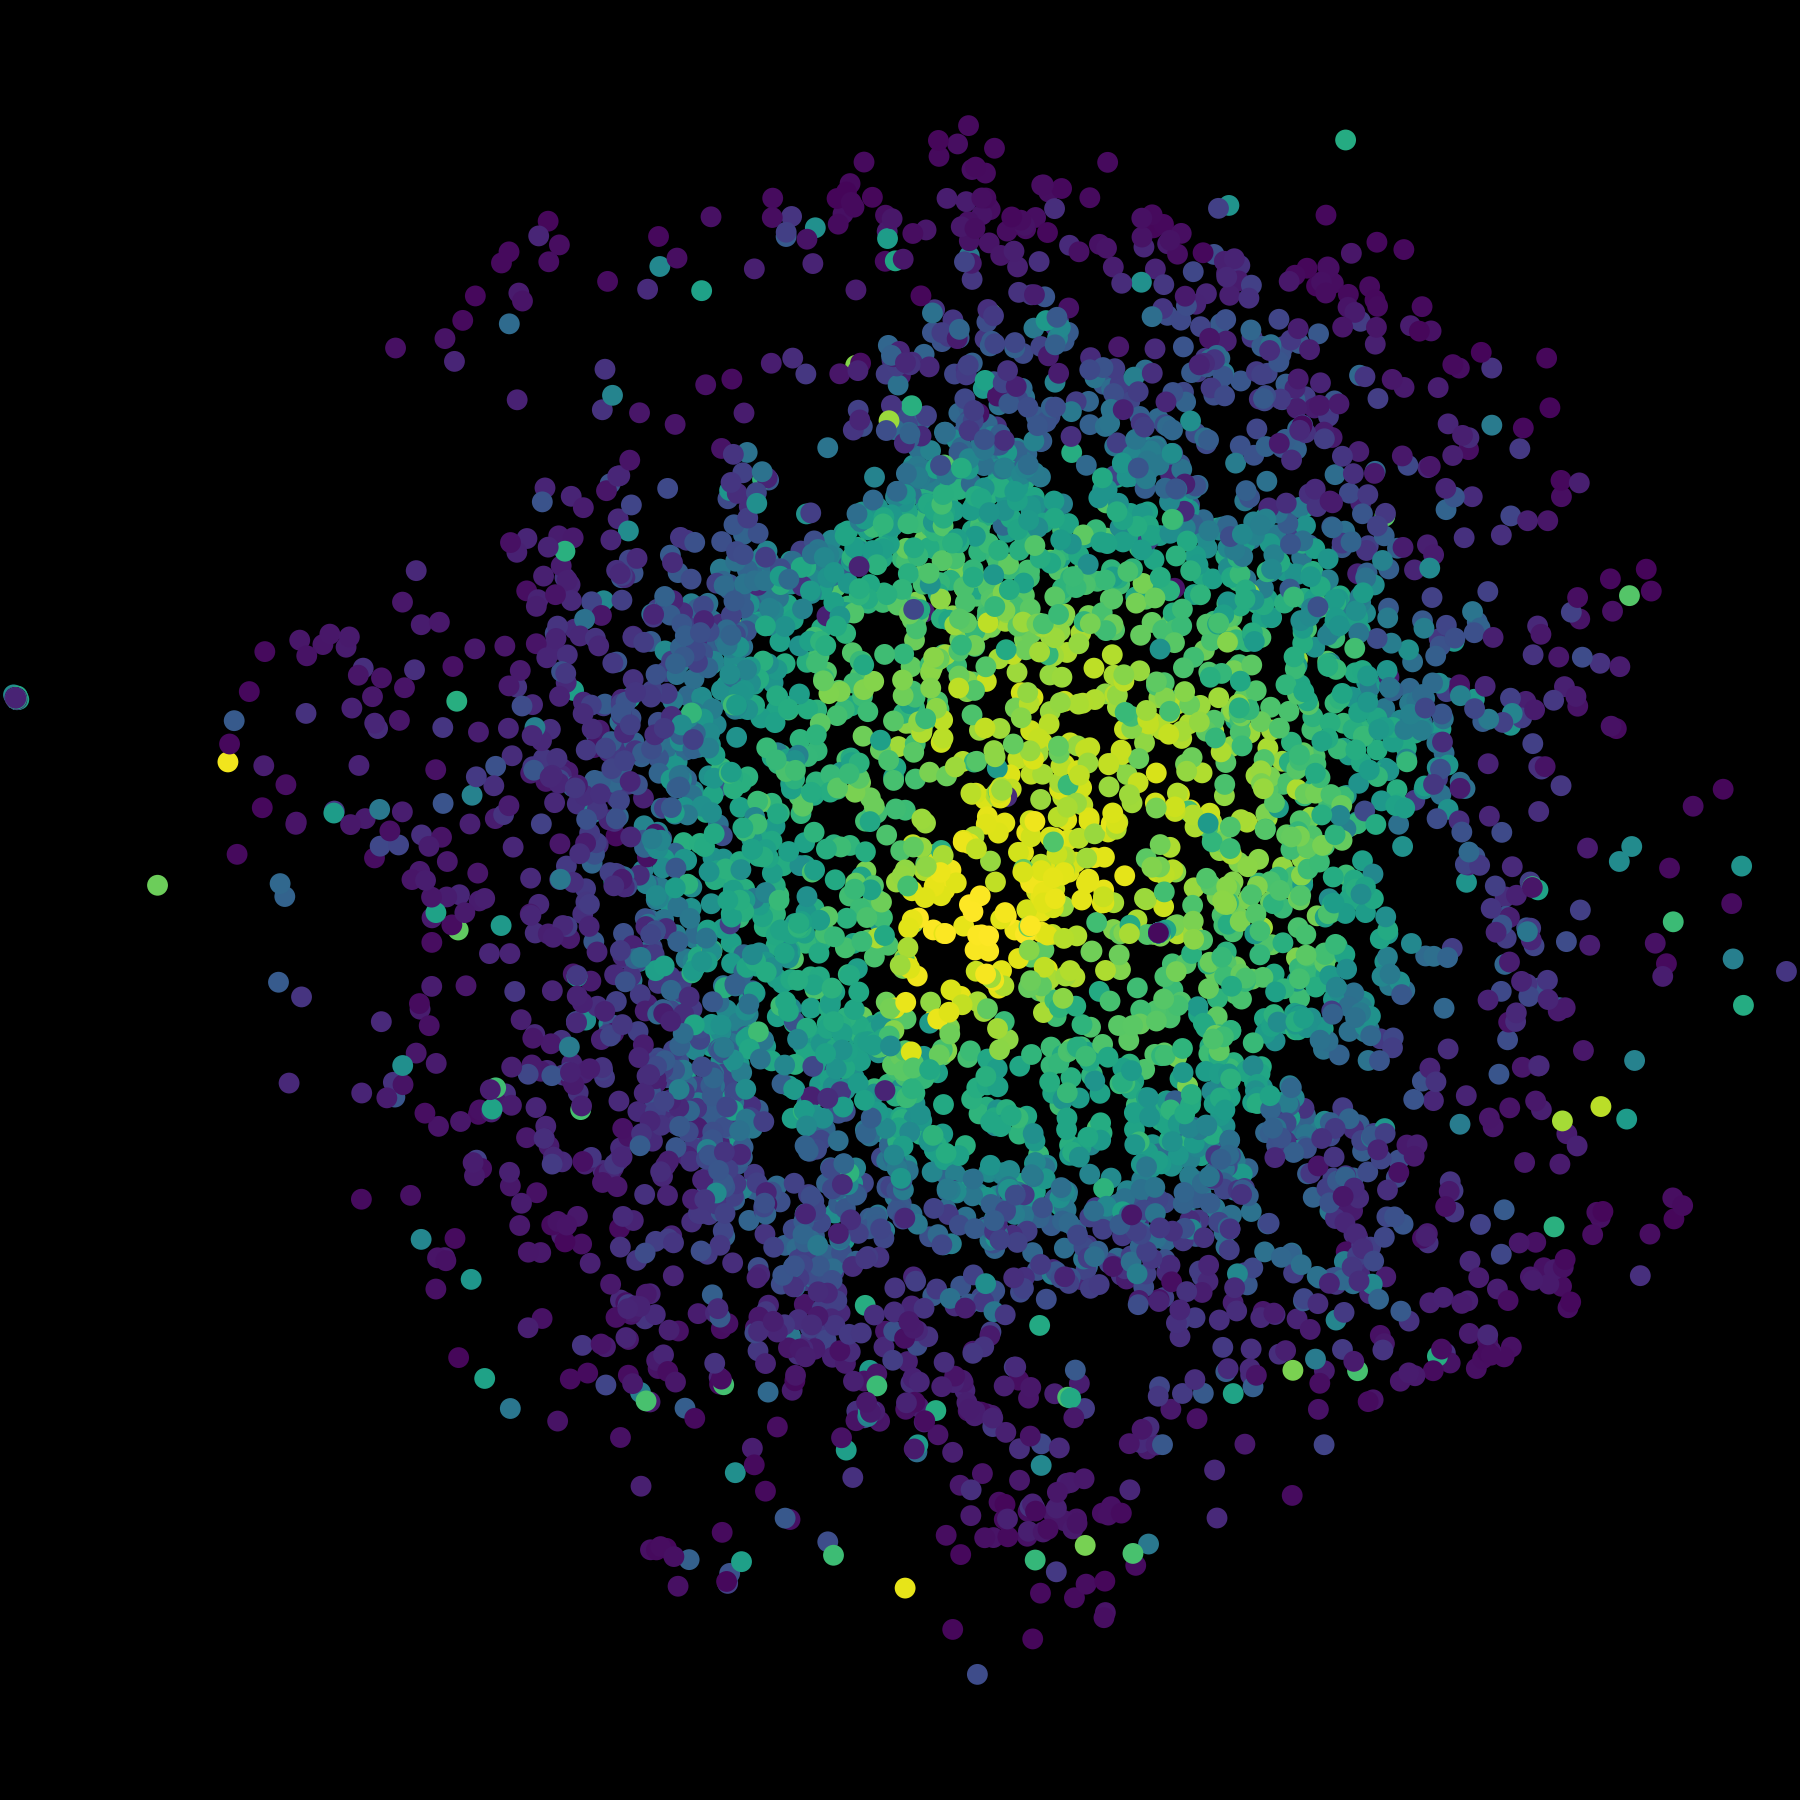

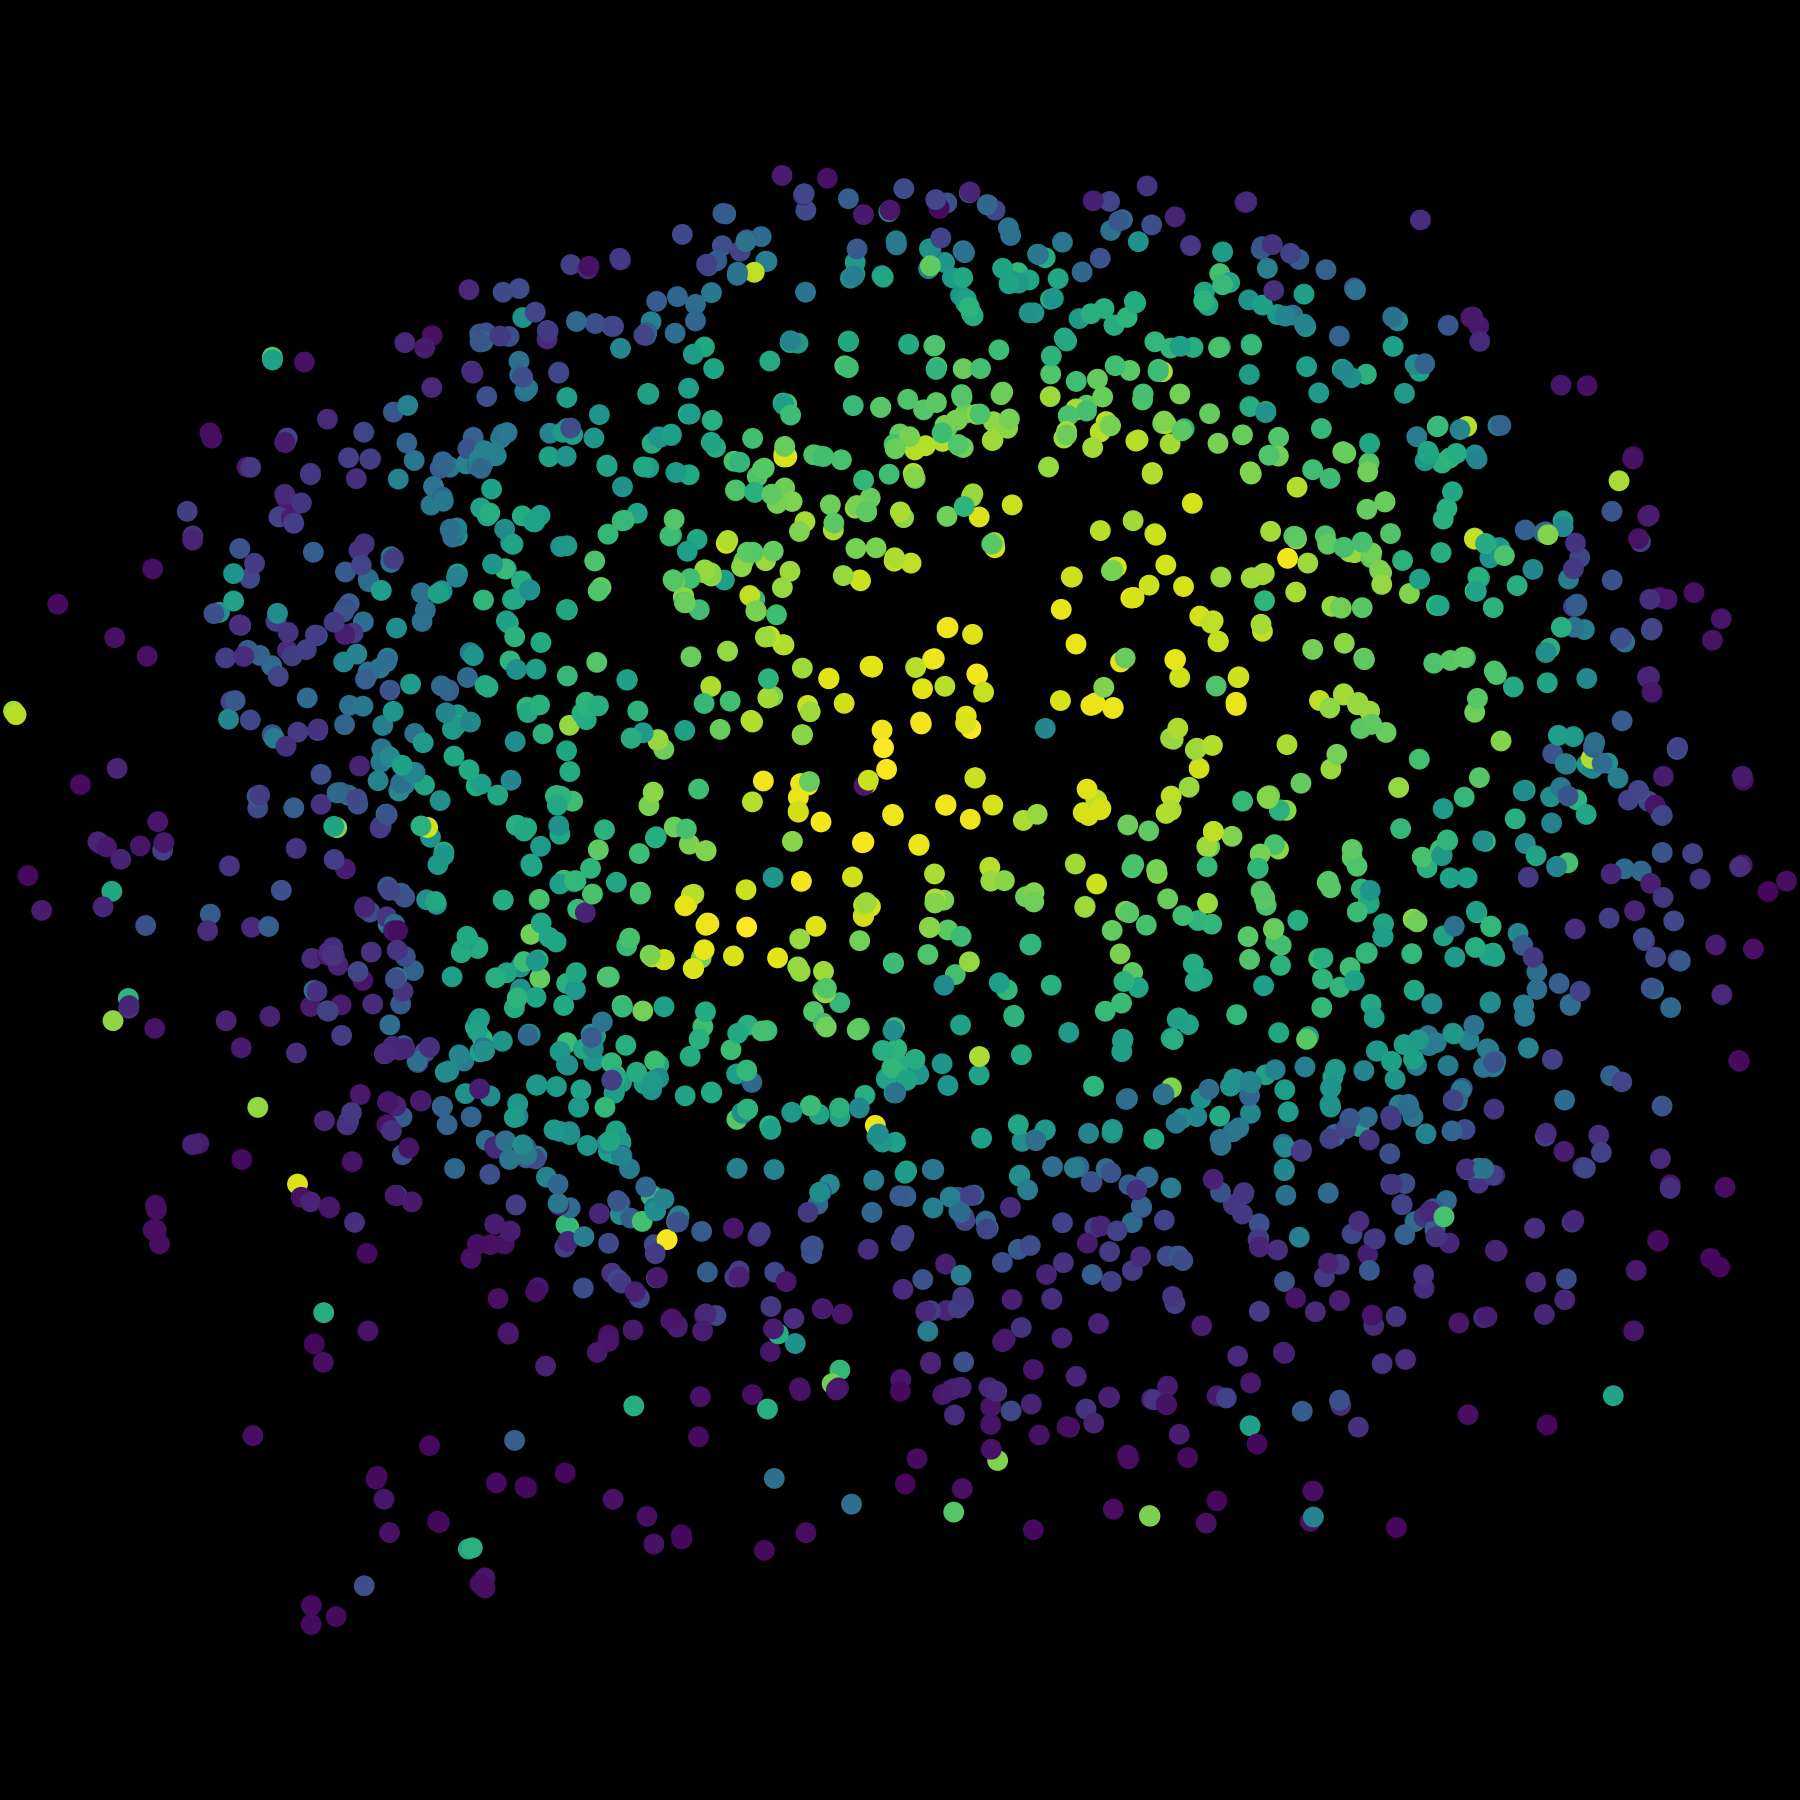

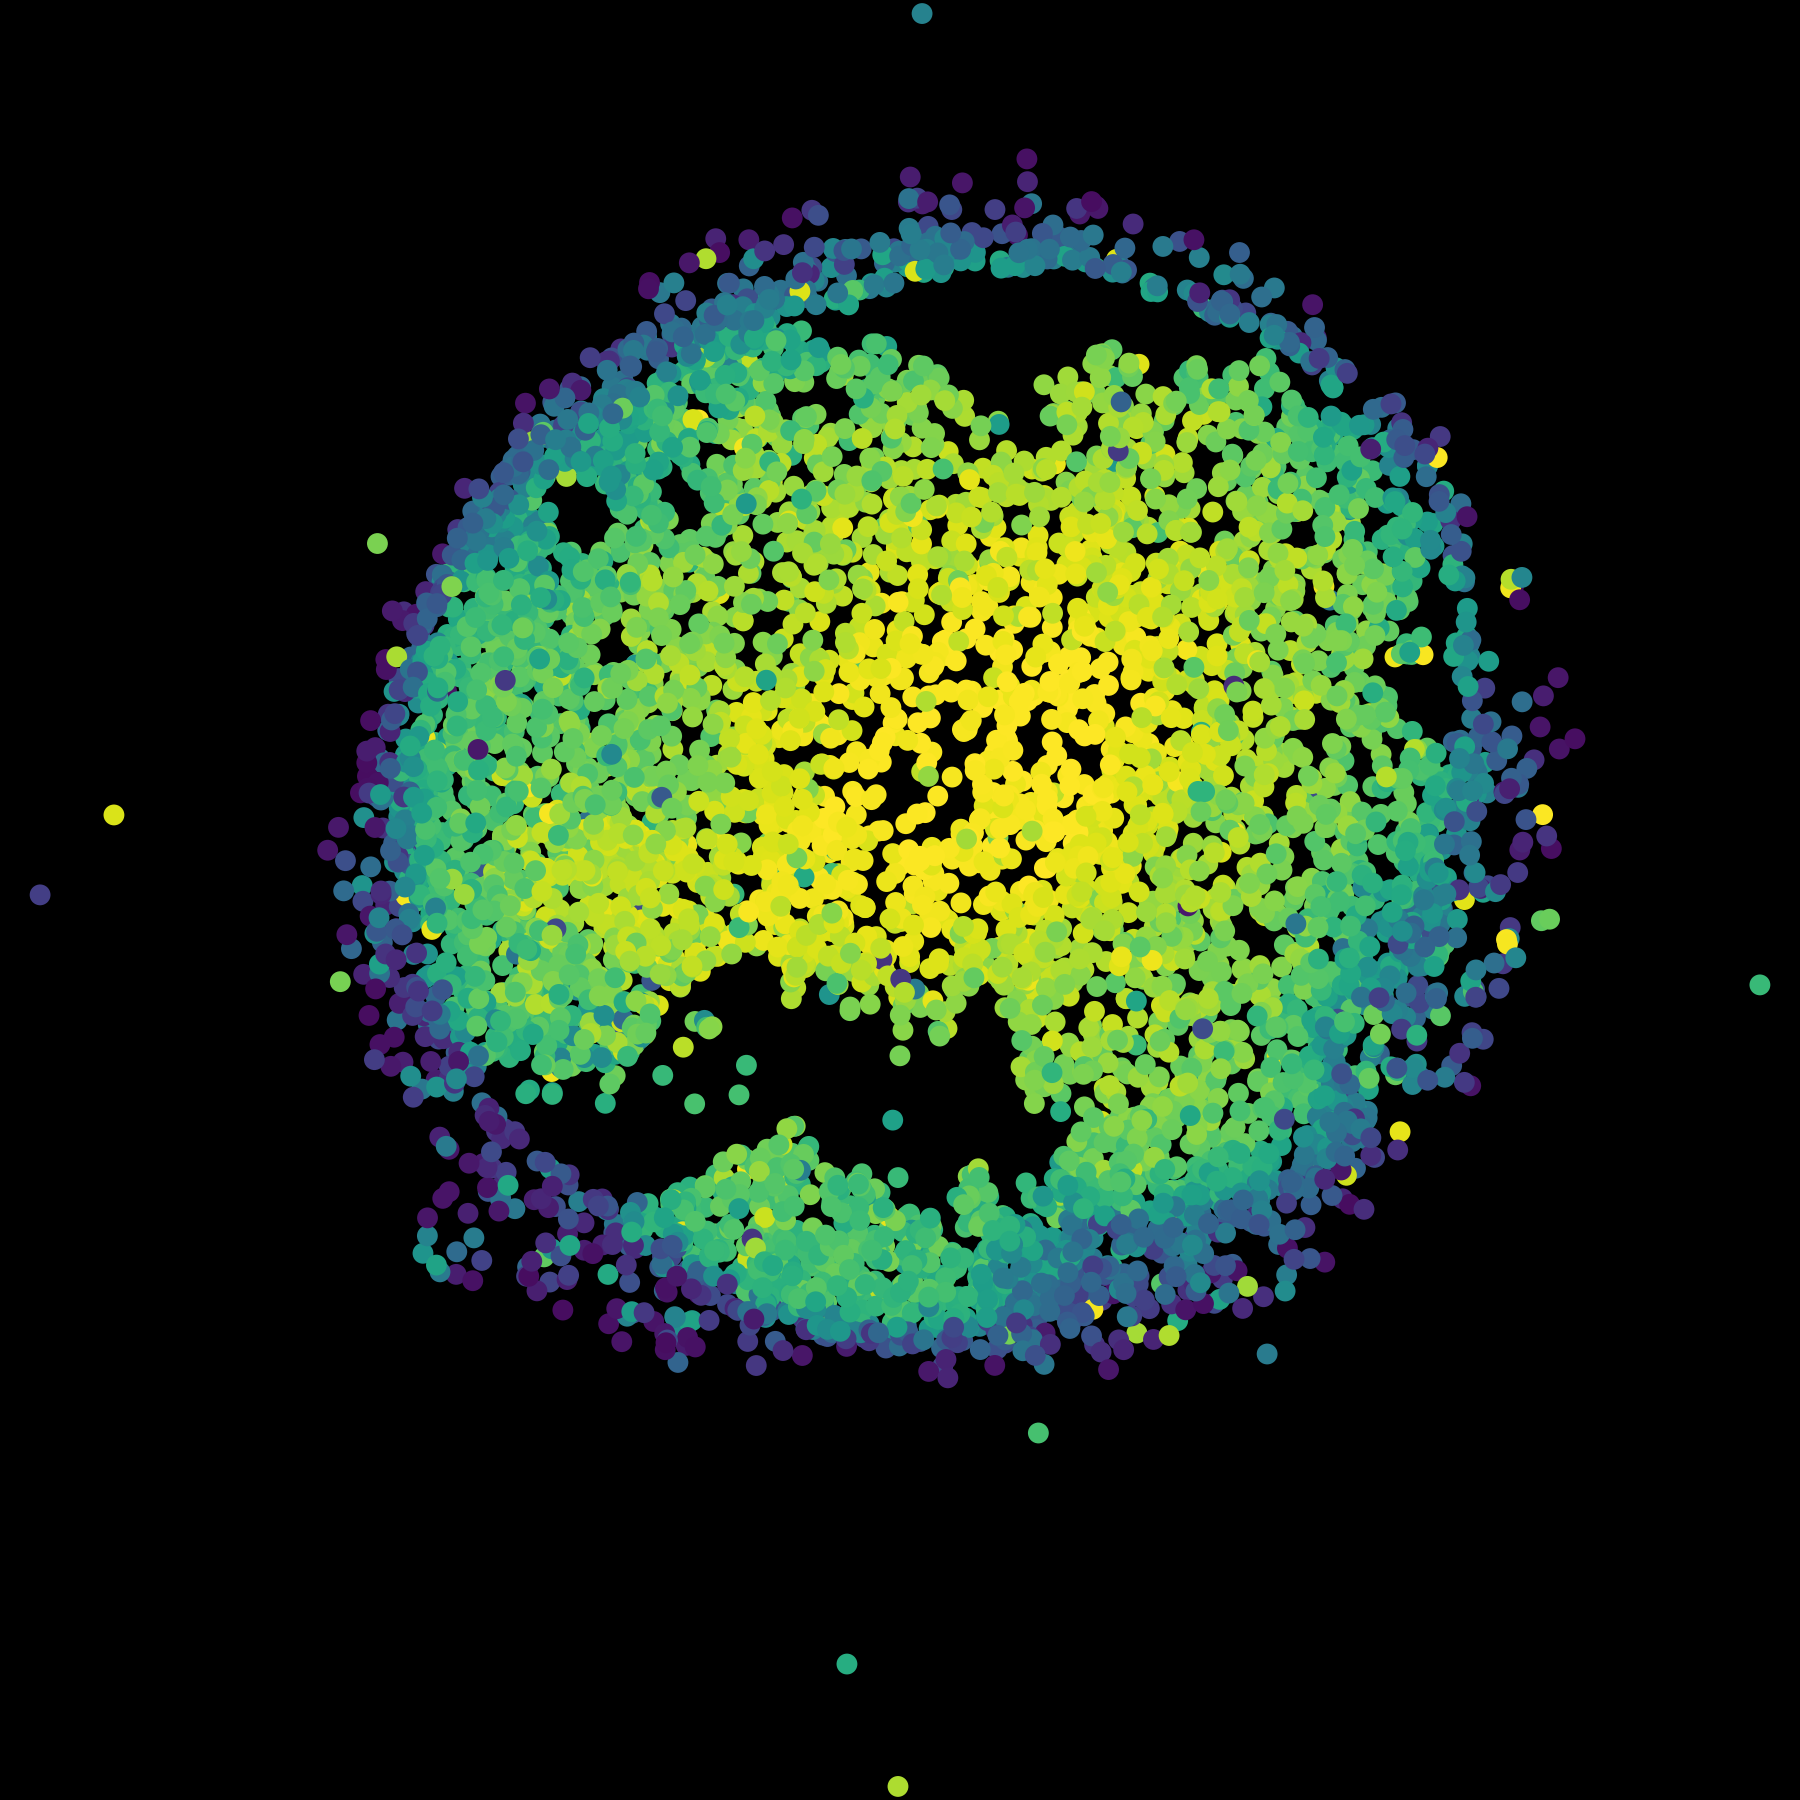

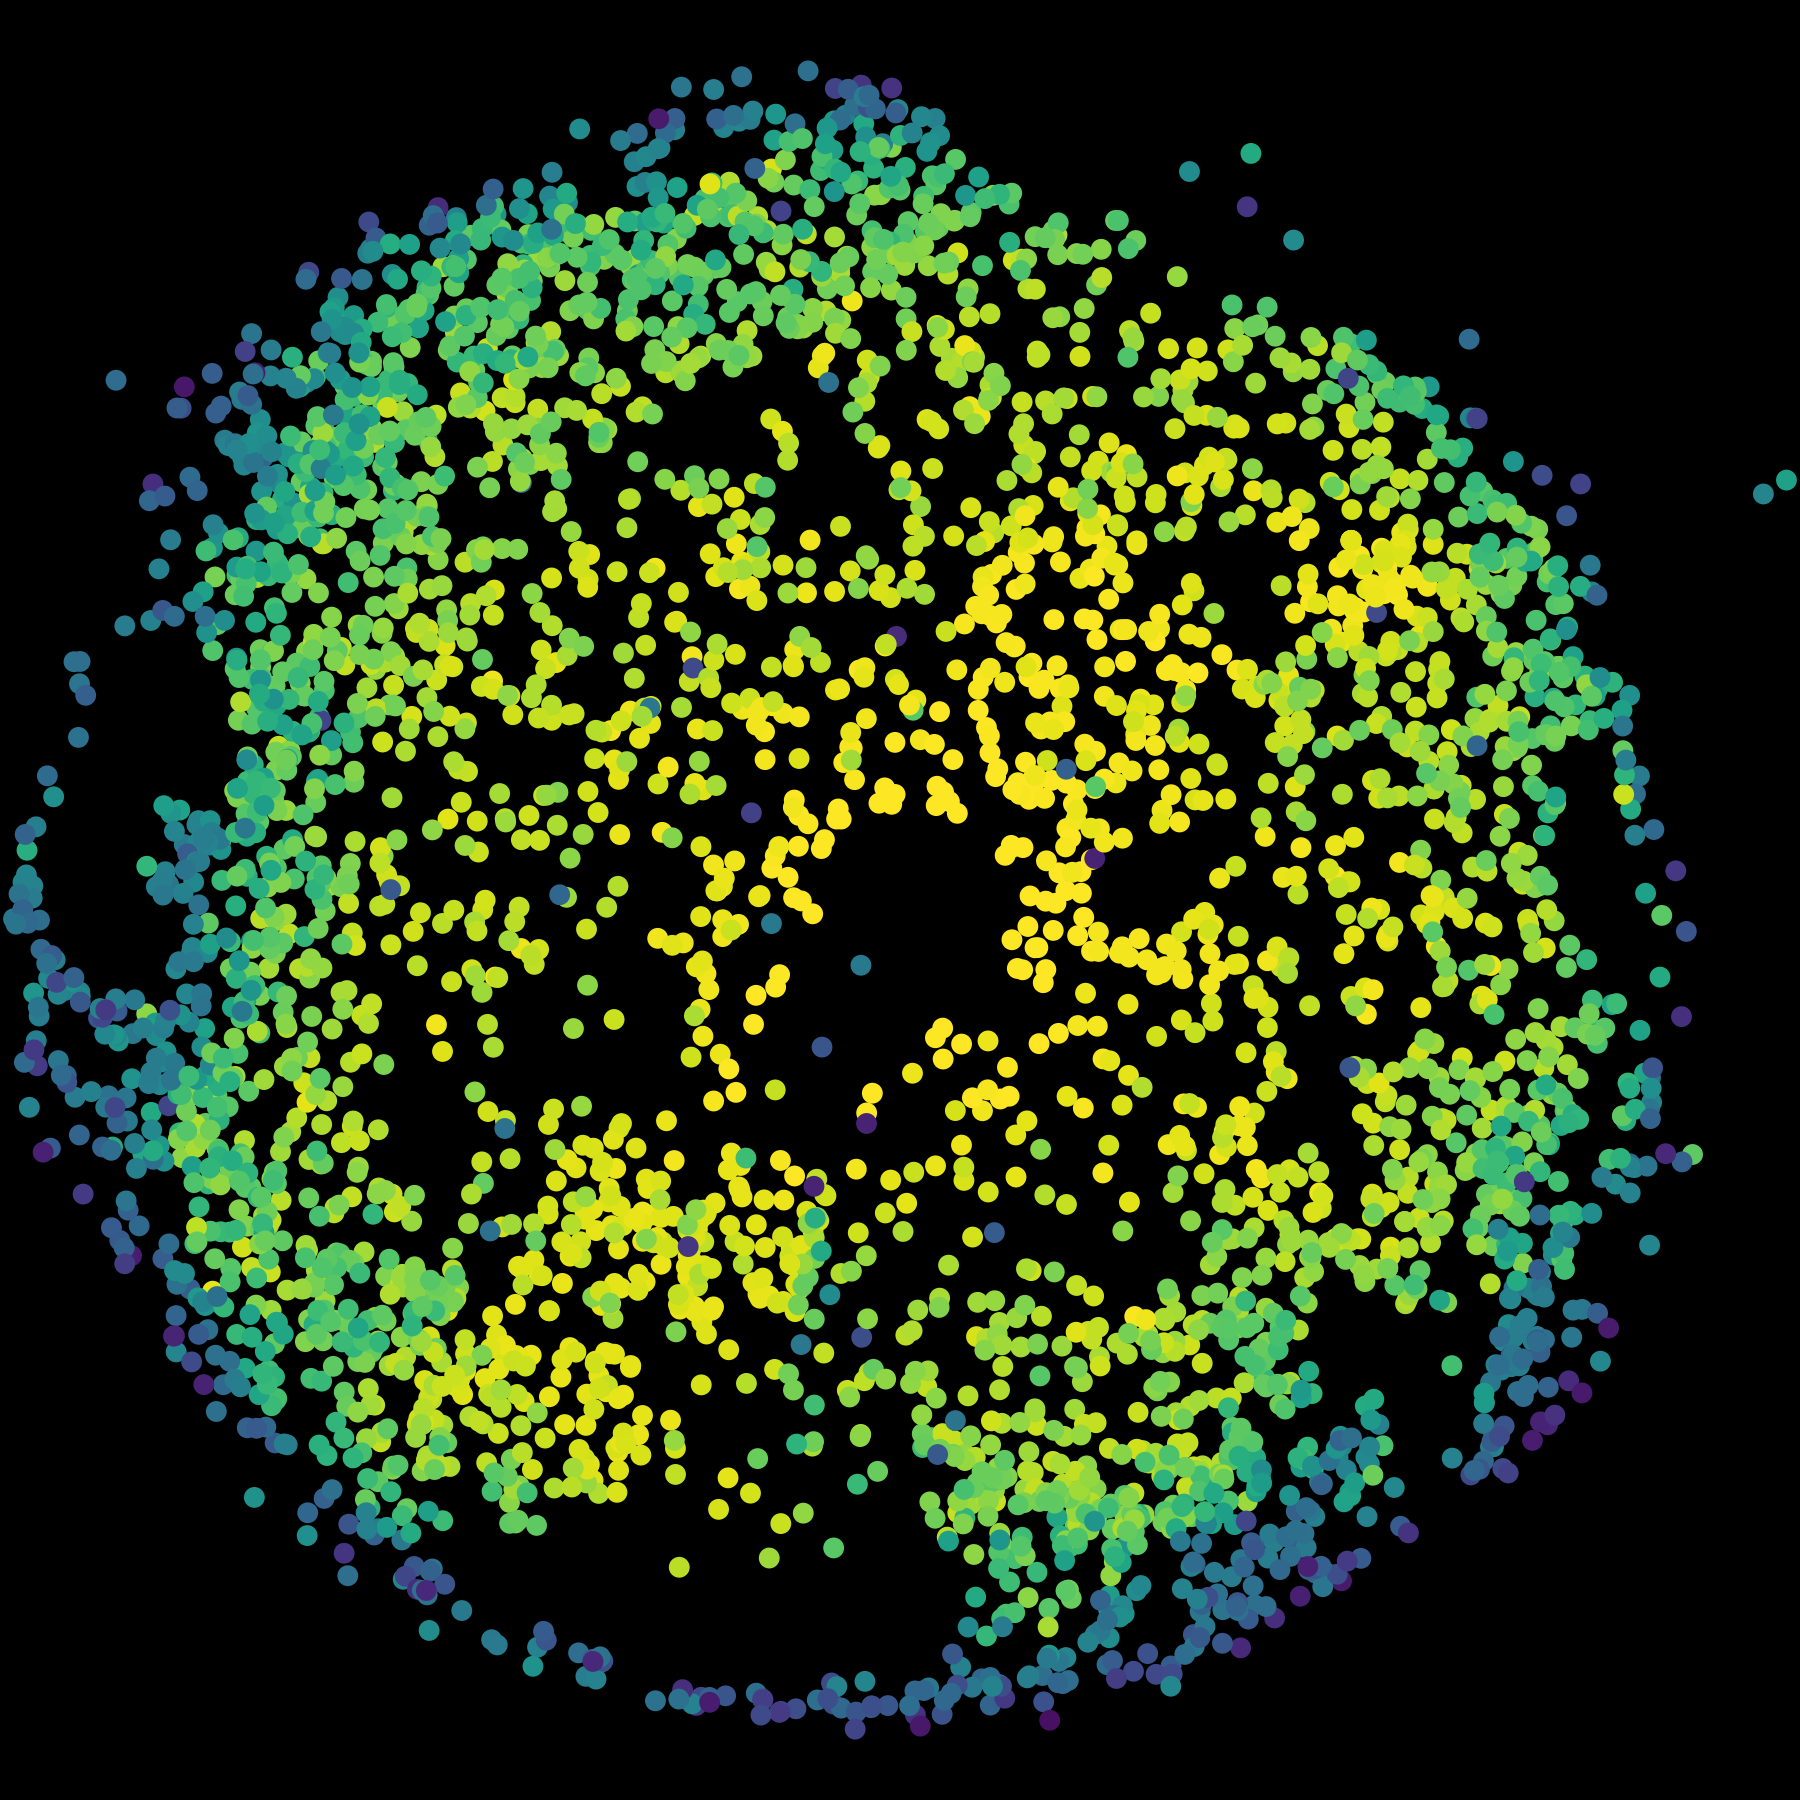

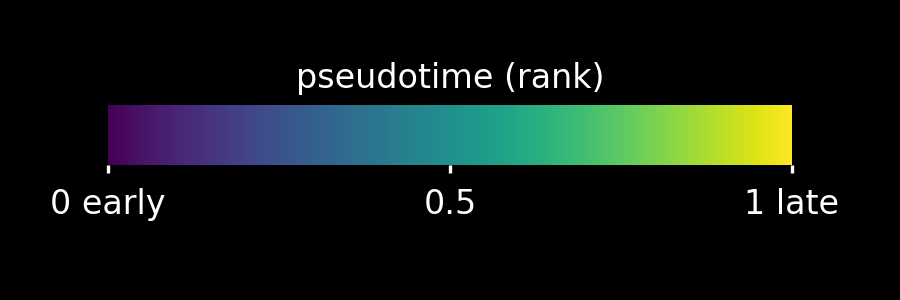

In [3]:
CMAP = mpl.colormaps["viridis"]
NORM = mpl.colors.Normalize(0, 1)
TEXT = "white"
PANEL_IN = 6
DPI = 300
DOT = 25             # pt^2 on the 6 in panel, as in the cell-type panels

# Per timepoint (object names): the libraries, crop (x and y limits in µm; None for the whole array) and
# counter-clockwise rotation. Crops and angles from the cell-type section panels (Ç. Cevrim, 11 Oct 2026).
SECTIONS = {
    "uninduced": {"samples": ["uninduced_mck8a", "uninduced_mck8b"], "limits": [(3350, 5850), (500, 3000)],
                  "rotation": 322.75},
    "1.5dpi_early": {"samples": ["1.5dpi_early_mck1"], "limits": [(1000, 3000), (1000, 3000)], "rotation": 28},
    "1.5dpi_late": {"samples": ["1.5dpi_late_mck12a", "1.5dpi_late_mck12b"], "limits": None, "rotation": 303},
    "2.5dpi": {"samples": ["2.5dpi_mck15"], "limits": [(2000, 9500), (500, 6500)], "rotation": 175},
    "3.5dpi": {"samples": ["3.5dpi_mck10a", "3.5dpi_mck10b"], "limits": [(1250, 8500), (1250, 8500)],
               "rotation": 135},
    "4.5dpi_menstrual": {"samples": ["4.5dpi_menstrual_mck11a"], "limits": None, "rotation": 81},
}
unknown = set(positioned["sample"].astype(str)) - {s for spec in SECTIONS.values() for s in spec["samples"]}
assert not unknown, f"samples without a section entry: {sorted(unknown)}"


def rotate(x, y, degrees, cx, cy):
    """Rotate points counter-clockwise by `degrees` about (cx, cy)."""
    if degrees % 360 == 0:
        return x, y
    t = np.deg2rad(degrees)
    return (x - cx) * np.cos(t) - (y - cy) * np.sin(t) + cx, (x - cx) * np.sin(t) + (y - cy) * np.cos(t) + cy


def section_frame(cells: pd.DataFrame, limits, degrees) -> pd.DataFrame:
    """Nuclei inside the crop, with display coordinates xr, yr (µm) rotated about the crop's center."""
    x, y = cells["x_um_dbscan"].to_numpy(float), cells["y_um_dbscan"].to_numpy(float)
    if limits is not None:
        (x0, x1), (y0, y1) = limits
        keep = (x >= x0) & (x <= x1) & (y >= y0) & (y <= y1)
        cells, x, y = cells[keep], x[keep], y[keep]
        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    else:
        cx, cy = (x.min() + x.max()) / 2, (y.min() + y.max()) / 2
    xr, yr = rotate(x, y, degrees, cx, cy)
    return cells.assign(xr=xr, yr=yr)


def marker_padding(span_x, span_y) -> tuple:
    """Pad the data range by one marker radius (+2 px) so edge dots are not clipped on the bare panel."""
    radius_px = np.sqrt(DOT / np.pi) / 72 * DPI + 2
    side_px = PANEL_IN * DPI

    def pad(span):
        return max(0.005 * span, radius_px / side_px * span)

    return pad(span_x), pad(span_y)


def spatial_panel(frame: pd.DataFrame, path: Path) -> list:
    """Bare black square framed on all nuclei of the crop; the apoptotic ones are not drawn."""
    fig, ax = plt.subplots(figsize=(PANEL_IN, PANEL_IN), facecolor="black")
    ax.set_position([0, 0, 1, 1])
    ax.set_facecolor("black")
    pad_x, pad_y = marker_padding(np.ptp(frame.xr), np.ptp(frame.yr))
    ax.set_xlim(frame.xr.min() - pad_x, frame.xr.max() + pad_x)
    ax.set_ylim(frame.yr.min() - pad_y, frame.yr.max() + pad_y)
    ax.set_aspect("equal", adjustable="box")
    ax.axis("off")
    drawn = frame[frame["cell_subtype"].astype(str) != APOPTOTIC_SUBTYPE]
    values = drawn["pseudotime"].to_numpy(float)
    assert np.isfinite(values).all(), "a nucleus without a pseudotime reached the panel"
    ax.scatter(drawn.xr, drawn.yr, s=DOT, c=CMAP(NORM(values)), linewidths=0)
    written = [path.with_suffix(f".{ext}") for ext in ("png", "pdf", "svg")]
    for out_path in written:
        fig.savefig(out_path, dpi=DPI, facecolor="black")
    plt.close(fig)
    return written


def color_key(path: Path) -> list:
    """Horizontal color key for the section panels."""
    fig = plt.figure(figsize=(3.0, 1.0), facecolor="black")
    cax = fig.add_axes([0.12, 0.45, 0.76, 0.2])
    bar = fig.colorbar(mpl.cm.ScalarMappable(norm=NORM, cmap=CMAP), cax=cax, orientation="horizontal",
                       ticks=[0, 0.5, 1])
    bar.ax.set_xticklabels(["0 early", "0.5", "1 late"], color=TEXT, fontsize=8)
    bar.outline.set_visible(False)
    bar.ax.tick_params(color=TEXT, length=2)
    cax.set_title("pseudotime (rank)", color=TEXT, fontsize=8, pad=4)
    written = [path.with_suffix(f".{ext}") for ext in ("png", "pdf", "svg")]
    for out_path in written:
        fig.savefig(out_path, dpi=300, facecolor="black")
    plt.close(fig)
    return written


files, counts = [], {}
for timepoint, spec in SECTIONS.items():
    cells = positioned[positioned["sample"].astype(str).isin(spec["samples"])]
    frame = section_frame(cells, spec["limits"], spec["rotation"])
    files += spatial_panel(frame, OUT / f"Fig4D_{DATE}-Mouse-{timepoint}-pseudotime-spatial.png")
    apoptotic_in_crop = int((frame["cell_subtype"].astype(str) == APOPTOTIC_SUBTYPE).sum())
    counts[timepoint] = {"libraries": spec["samples"], "positioned": len(cells), "in_crop": len(frame),
                         "apoptotic_not_drawn": apoptotic_in_crop, "drawn": len(frame) - apoptotic_in_crop,
                         "median_pseudotime": round(float(frame["pseudotime"].median()), 4),
                         "limits_um": spec["limits"], "rotation_deg_ccw": spec["rotation"]}
    print(f"4D {timepoint}: {counts[timepoint]}")
files += color_key(OUT / f"Fig4D_{DATE}-spatial_key_pseudotime.png")

record = {"panel": "Fig4D_pseudotime_spatial", "written": datetime.datetime.now().isoformat(timespec="seconds"),
          "host": platform.node(), "notebook": "figures/Fig4_mouse_decidual_maturation.ipynb",
          "inputs": [file_record(Path(MOUSE), "mouse_pseudotime_object")],
          "outputs": [str(p.resolve()) for p in files], "font": font,
          "positions": "x_um_dbscan, y_um_dbscan (Slide-tags DBSCAN positions; no spatial QC)",
          "pseudotime_column": "pseudotime", "rescaled_or_reranked": False, "colormap": "viridis, fixed 0-1",
          "not_drawn": f"cell_subtype {APOPTOTIC_SUBTYPE} (no pseudotime)",
          "sections": counts, "panel_in": PANEL_IN, "dpi": DPI, "dot_pt2": DOT,
          "versions": {"python": platform.python_version(), "scanpy": sc.__version__, "matplotlib": mpl.__version__,
                       "pandas": pd.__version__}}
(OUT / "Fig4D_pseudotime_spatial.provenance.json").write_text(json.dumps(record, indent=1, default=str))
for path in files[::3]:
    display(Image(filename=str(path), width=260))

## Compare with the files of record

4D has no file of record yet; 4H's files are drawn by `pt_heatmaps/`. Before copying 4D into `final_figures`, check
the sections against Fig. 4C of the manuscript (same crops and angles) and the counts above against the object.

In [ ]:
print("wrote", sorted(p.name for p in OUT.iterdir()))